# What makes a country happy? World Happiness 2015–2019 + socioeconomic indicators

**Questions**
1. How is happiness distributed across countries and regions, and has it changed since 2015?
2. Which factors move together with the happiness score?
3. How strongly do income (GDP per capita) and health (life expectancy) relate to happiness?
4. Which countries gained or lost the most between 2015 and 2019?

**Data** – World Happiness Report 2015–2019 (Kaggle), GDP per capita PPP (World Bank via Our World in Data),
and World Bank development indicators. The cleaning/merging logic lives in `scripts/data_prep.py`.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from scripts.data_prep import build_dataset, save_processed

sns.set_theme(style='whitegrid', context='notebook')
FIG = Path('reports/figures'); FIG.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', dpi=140, bbox_inches='tight'); plt.show()

## 1. Load and merge

In [2]:
df = build_dataset()
save_processed(df)
print(f'{len(df)} rows, {df.country.nunique()} countries, years {df.year.min()}–{df.year.max()}')
df.head()

782 rows, 164 countries, years 2015–2019


,country,year,region,happiness_score,gdp_index,social_support,health_index,freedom,generosity,trust_in_government,iso_code,gdp_per_capita_ppp,life_expectancy,health_expenditure_pct,unemployment_pct,undernourishment_pct,sanitation_pct,income_group,wb_region,happiness_rank
0,Switzerland,2015,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,CHE,77257.680,82.897561,11.007950,4.80,2.5,99.632888,High income,Europe & Central Asia,1
1,Iceland,2015,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,ISL,60262.523,82.468293,8.069790,3.98,2.5,73.986008,High income,Europe & Central Asia,2
2,Denmark,2015,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,DNK,62450.020,80.702439,10.227166,6.28,2.5,90.443012,High income,Europe & Central Asia,3
3,Norway,2015,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,NOR,85766.610,82.304878,10.131469,4.30,2.5,63.650549,High income,Europe & Central Asia,4
4,Canada,2015,North America,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,CAN,54819.188,81.900000,10.733205,6.91,2.5,82.803878,High income,North America,5


## 2. Data quality
The happiness scores themselves are complete. The gaps are in the World Bank indicators: some countries
(e.g. Egypt, Iran, Russia, South Korea, Turkey) are simply not in the World Bank file I used, and
sanitation / undernourishment are sparsely reported. I keep those rows rather than dropping them and
exclude missing values only per analysis.

In [3]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print('Duplicate country-year rows:', df.duplicated(['country', 'year']).sum())
print('Countries per year:', df.groupby('year').size().to_dict())
missing[missing > 0].to_frame('% missing')

Duplicate country-year rows: 0
Countries per year: {2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156}


,% missing
sanitation_pct,39.8
undernourishment_pct,21.7
health_expenditure_pct,13.9
life_expectancy,12.4
income_group,12.4
wb_region,12.4
unemployment_pct,12.4
gdp_per_capita_ppp,3.3
iso_code,0.9
trust_in_government,0.1


## 3. Distribution of happiness scores

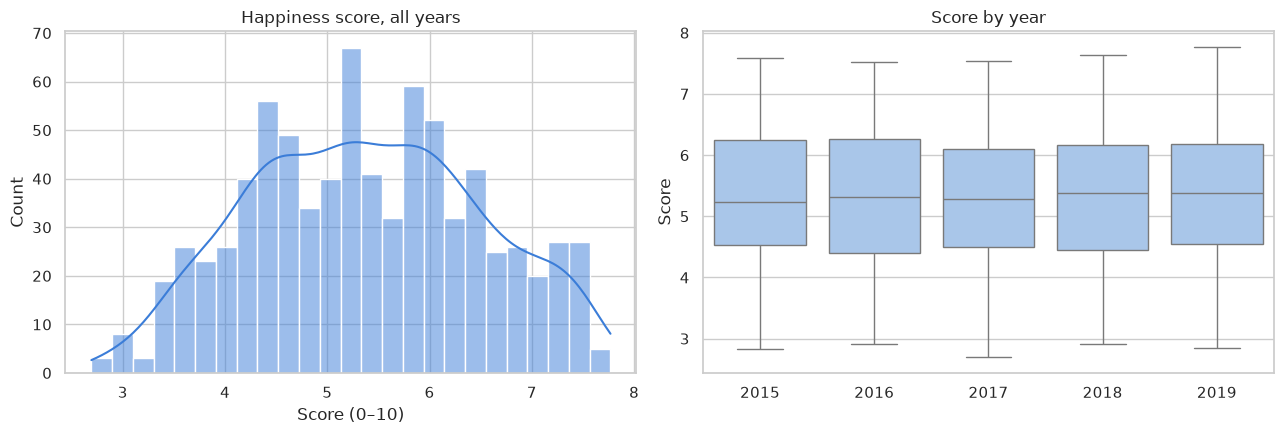

,mean,median,std,min,max
year,,,,,
2015,5.376,5.232,1.145,2.839,7.587
2016,5.382,5.314,1.142,2.905,7.526
2017,5.354,5.279,1.131,2.693,7.537
2018,5.376,5.378,1.120,2.905,7.632
2019,5.407,5.380,1.113,2.853,7.769


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df.happiness_score, bins=25, kde=True, ax=ax[0], color='#3b7dd8')
ax[0].set(title='Happiness score, all years', xlabel='Score (0–10)')
sns.boxplot(data=df, x='year', y='happiness_score', ax=ax[1], color='#9ec5f4')
ax[1].set(title='Score by year', xlabel='', ylabel='Score')
save('01_score_distribution')
df.groupby('year').happiness_score.agg(['mean', 'median', 'std', 'min', 'max']).round(3)

## 4. Happiest and least happy countries (2019)

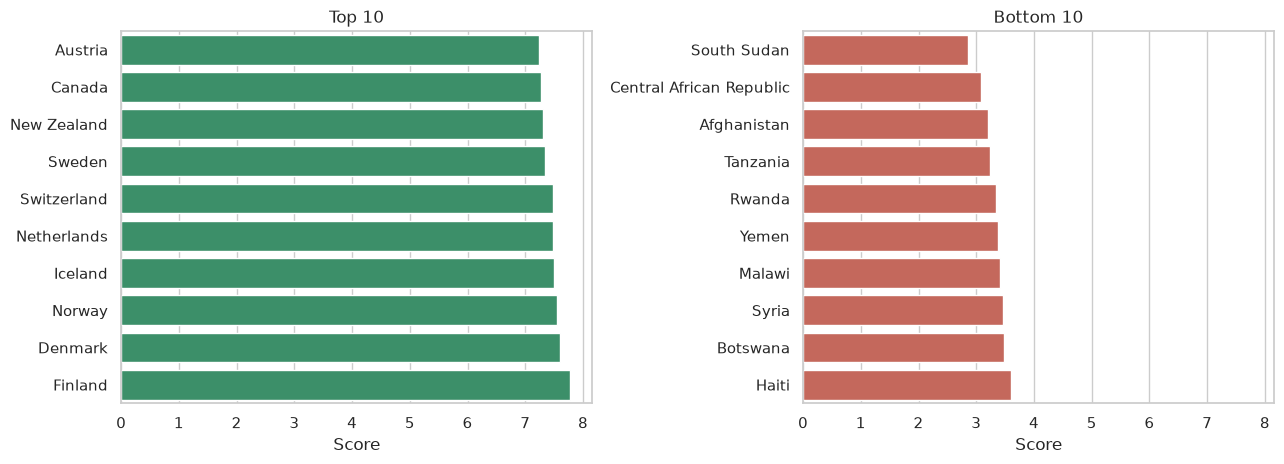

In [5]:
d19 = df[df.year == 2019].sort_values('happiness_score')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
sns.barplot(data=d19.tail(10), y='country', x='happiness_score', ax=ax[0], color='#2e9d6a')
ax[0].set(title='Top 10', xlabel='Score', ylabel='')
sns.barplot(data=d19.head(10), y='country', x='happiness_score', ax=ax[1], color='#d65a4a')
ax[1].set(title='Bottom 10', xlabel='Score', ylabel='')
save('02_top_bottom_2019')

## 5. Regional differences (2019)

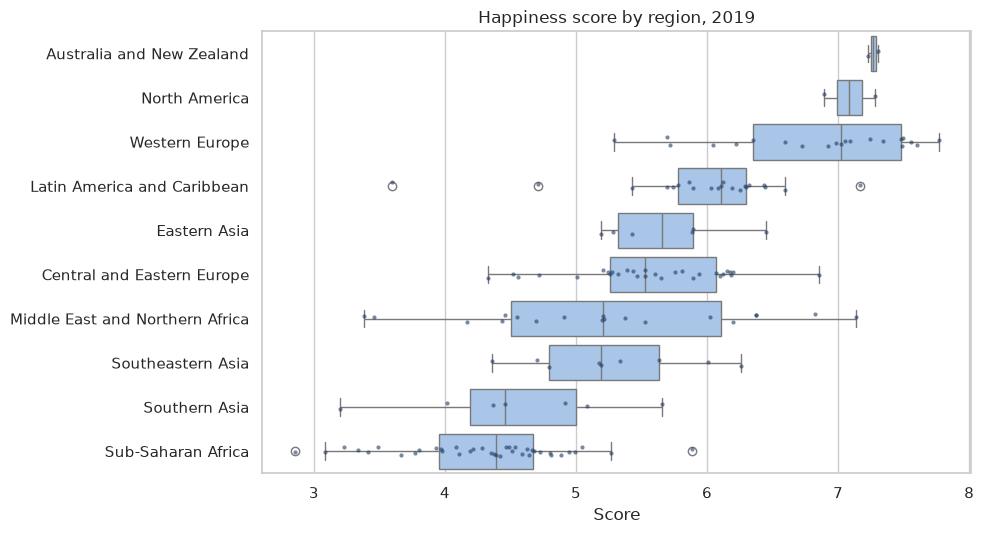

,count,median
region,,
Australia and New Zealand,2,7.27
North America,2,7.08
Western Europe,21,7.02
Latin America and Caribbean,21,6.10
Eastern Asia,6,5.66
Central and Eastern Europe,29,5.53
Middle East and Northern Africa,19,5.21
Southeastern Asia,9,5.19
Southern Asia,7,4.46


In [6]:
order = d19.groupby('region').happiness_score.median().sort_values(ascending=False).index
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=d19, y='region', x='happiness_score', order=order, color='#9ec5f4')
sns.stripplot(data=d19, y='region', x='happiness_score', order=order, color='#1f3b63', size=3, alpha=.6)
plt.title('Happiness score by region, 2019'); plt.xlabel('Score'); plt.ylabel('')
save('03_regions_2019')
d19.groupby('region').happiness_score.agg(['count', 'median']).sort_values('median', ascending=False).round(2)

## 6. What moves with happiness? Correlations

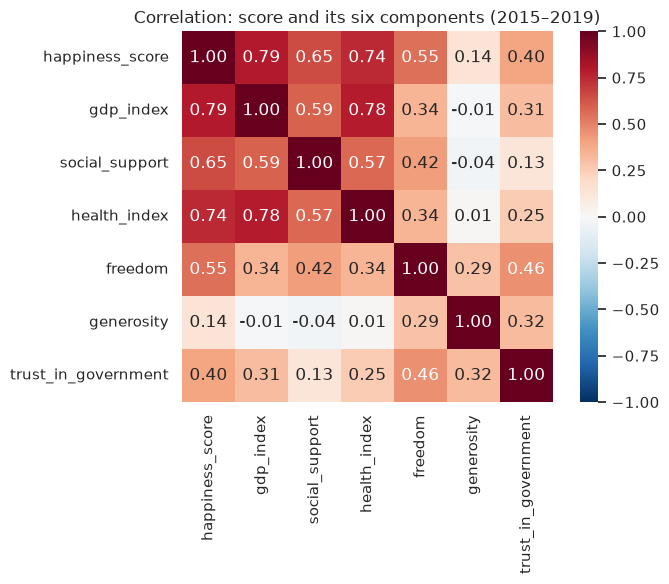

gdp_index              0.789
health_index           0.742
social_support         0.649
freedom                0.551
trust_in_government    0.398
generosity             0.138
Name: happiness_score, dtype: float64

In [7]:
factors = ['gdp_index', 'social_support', 'health_index', 'freedom', 'generosity', 'trust_in_government']
corr = df[['happiness_score'] + factors].corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Correlation: score and its six components (2015–2019)')
save('04_correlation_heatmap')
corr['happiness_score'].drop('happiness_score').sort_values(ascending=False).round(3)

## 7. Income and happiness

Pearson (linear GDP): 0.738 | Pearson (log GDP): 0.812 | Spearman: 0.819


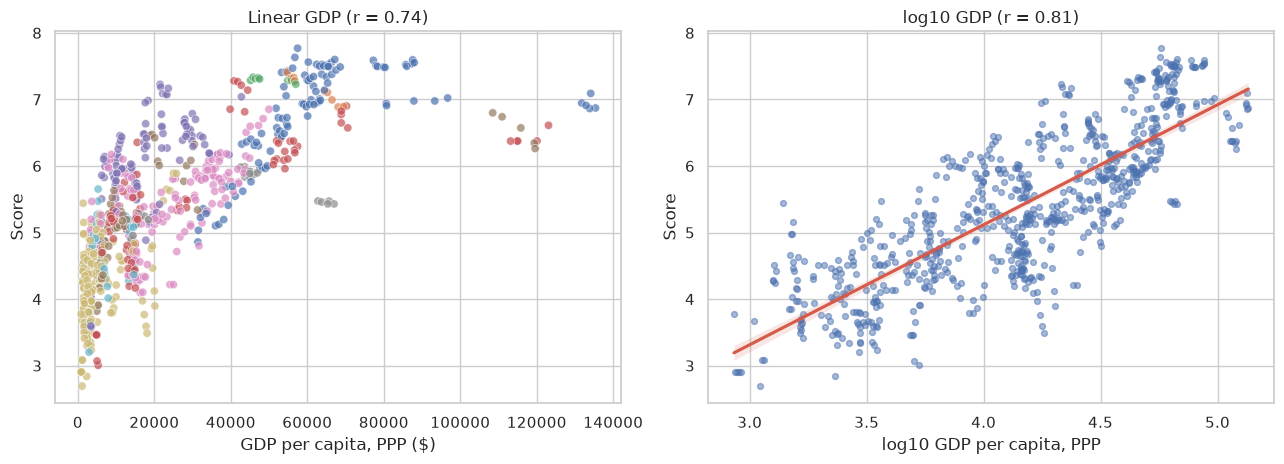

In [8]:
inc = df.dropna(subset=['gdp_per_capita_ppp']).copy()
inc['log_gdp'] = np.log10(inc.gdp_per_capita_ppp)
r_lin = stats.pearsonr(inc.gdp_per_capita_ppp, inc.happiness_score)[0]
r_log = stats.pearsonr(inc.log_gdp, inc.happiness_score)[0]
rho = stats.spearmanr(inc.gdp_per_capita_ppp, inc.happiness_score)[0]
print(f'Pearson (linear GDP): {r_lin:.3f} | Pearson (log GDP): {r_log:.3f} | Spearman: {rho:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=inc, x='gdp_per_capita_ppp', y='happiness_score', hue='region', ax=ax[0], legend=False, alpha=.7)
ax[0].set(title=f'Linear GDP (r = {r_lin:.2f})', xlabel='GDP per capita, PPP ($)', ylabel='Score')
sns.regplot(data=inc, x='log_gdp', y='happiness_score', ax=ax[1], scatter_kws=dict(alpha=.5, s=18), line_kws=dict(color='#d65a4a'))
ax[1].set(title=f'log10 GDP (r = {r_log:.2f})', xlabel='log10 GDP per capita, PPP', ylabel='Score')
save('05_gdp_vs_happiness')

## 8. Health and happiness

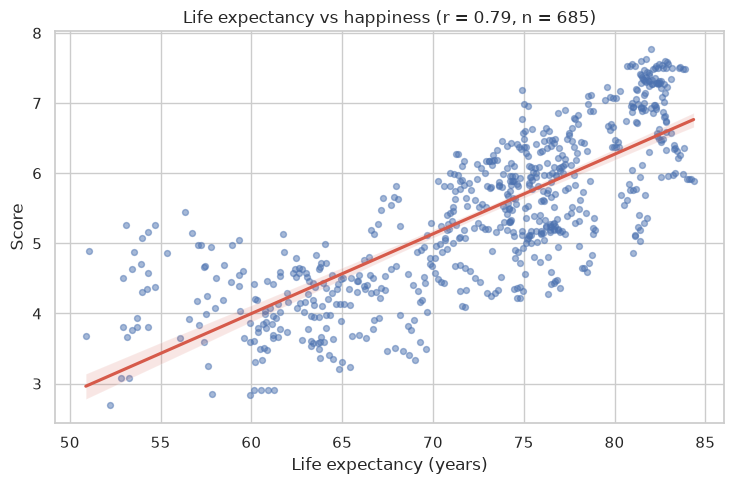

Income group medians:


,count,median
income_group,,
High income,222,6.54
Upper middle income,179,5.51
Lower middle income,184,4.79
Low income,100,3.97


In [9]:
hl = df.dropna(subset=['life_expectancy'])
r = stats.pearsonr(hl.life_expectancy, hl.happiness_score)[0]
plt.figure(figsize=(7.5, 5))
sns.regplot(data=hl, x='life_expectancy', y='happiness_score', scatter_kws=dict(alpha=.5, s=18), line_kws=dict(color='#d65a4a'))
plt.title(f'Life expectancy vs happiness (r = {r:.2f}, n = {len(hl)})'); plt.xlabel('Life expectancy (years)'); plt.ylabel('Score')
save('06_life_expectancy')
print('Income group medians:')
hl.groupby('income_group').happiness_score.agg(['count', 'median']).sort_values('median', ascending=False).round(2)

## 9. Biggest movers, 2015 → 2019

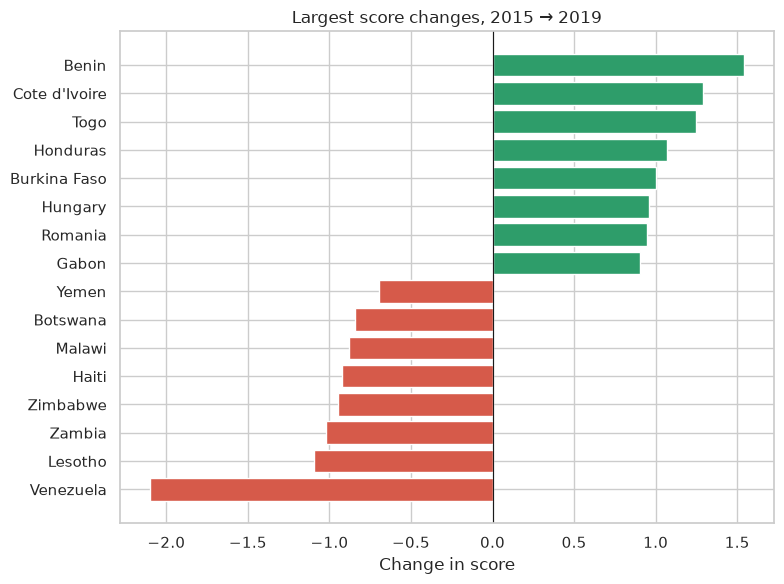

Average change across 152 countries: +0.057


year,2015,2019,change
country,,,
Venezuela,6.81,4.71,-2.10
Lesotho,4.90,3.80,-1.10
Zambia,5.13,4.11,-1.02
Togo,2.84,4.08,1.25
Cote d'Ivoire,3.66,4.94,1.29
Benin,3.34,4.88,1.54


In [10]:
wide = df.pivot(index='country', columns='year', values='happiness_score')[[2015, 2019]].dropna()
wide['change'] = wide[2019] - wide[2015]
movers = pd.concat([wide.sort_values('change').head(8), wide.sort_values('change').tail(8)])
plt.figure(figsize=(8, 6))
colors = ['#d65a4a' if v < 0 else '#2e9d6a' for v in movers.change]
plt.barh(movers.index, movers.change, color=colors)
plt.axvline(0, color='k', lw=.8); plt.title('Largest score changes, 2015 → 2019'); plt.xlabel('Change in score')
save('07_biggest_movers')
print(f'Average change across {len(wide)} countries: {wide.change.mean():+.3f}')
wide.sort_values('change').round(2).iloc[[0, 1, 2, -3, -2, -1]]

## 10. Which components matter most?
A linear regression on **standardised** inputs, so the coefficients are comparable. This describes association in
this dataset, not causation. Note the report's six components are themselves used to build the score, so a high R²
is expected; the useful part is the *relative* weight.

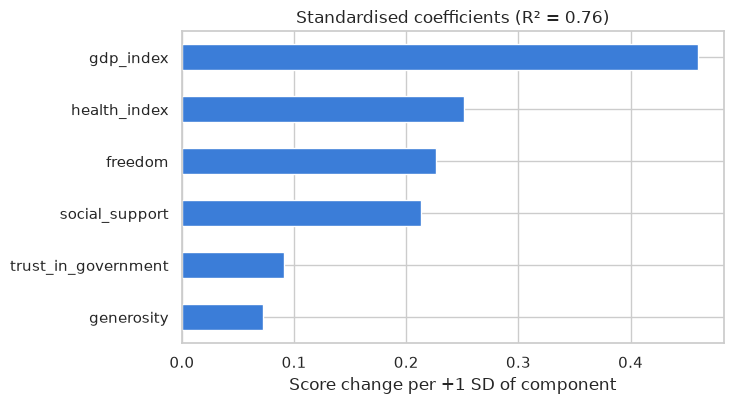

gdp_index              0.460
health_index           0.251
freedom                0.226
social_support         0.213
trust_in_government    0.091
generosity             0.072
dtype: float64

In [11]:
m = df.dropna(subset=factors + ['happiness_score'])
X = StandardScaler().fit_transform(m[factors]); y = m.happiness_score
model = LinearRegression().fit(X, y)
coef = pd.Series(model.coef_, index=factors).sort_values()
plt.figure(figsize=(7.5, 4.2))
coef.plot.barh(color='#3b7dd8'); plt.title(f'Standardised coefficients (R² = {model.score(X, y):.2f})')
plt.xlabel('Score change per +1 SD of component')
save('08_component_weights')
coef.sort_values(ascending=False).round(3)

## 11. Key findings

1. **Happiness is stable at the global level, unequal between regions.** The yearly mean barely moves (5.38 in 2015 → 5.41 in 2019). The gap between regions is large: Western Europe, North America and Australia/NZ have medians above 7.0, while Sub-Saharan Africa (4.39) and Southern Asia (4.46) sit about 2.6 points lower.
2. **Income is strongly related to happiness, with diminishing returns.** The correlation with GDP per capita is r = 0.74 on a linear scale but r = 0.81 on a log scale (Spearman 0.82): a doubling of income matters more at low incomes than at high ones. Median score rises from 3.97 (low income) to 6.54 (high income).
3. **Health goes with happiness almost as strongly.** Life expectancy correlates at r = 0.79 (n = 685 country-years).
4. **Among the survey components, GDP, healthy life expectancy and social support correlate most with the score** (0.79, 0.74, 0.65). Generosity is the weakest (0.14). In a joint regression (R² = 0.76) GDP carries the largest weight (0.46 per SD), followed by health (0.25), freedom (0.23) and social support (0.21).
5. **Movement is concentrated in a few countries.** Venezuela fell the most (6.81 → 4.71), followed by Lesotho and Zambia; Benin (+1.54), Côte d'Ivoire and Togo rose the most. The average change over 152 countries is only +0.06.
6. **Caveat:** these are associations from a survey-derived score, not causal effects.


## 12. Limitations
- Correlation, not causation; the six components and the score come from the same survey model.
- World Bank indicators are missing for ~12% of country-years (see section 2), so health/income-group results cover fewer countries.
- 2015–2019 only; the 2020+ reports use a different methodology and are not included.